In [28]:
import os

import pandas as pd
import numpy as np
from scipy.stats import entropy
import random
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import build_df
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    YEARS,
    NUM_CLUSTERS,
)

In [53]:
COLS = ["NL_OFF", "NL_ON", "NL_SOLAR", "NL_TEMP"]

In [29]:
centroid_years = pd.read_csv(os.path.join(BASE_OUTPUT, "centroids/centroid_years.csv"))
df_daily, df_nl_rolling = build_df()

In [ ]:
centroid_years["weighing_factor"] = (
    len(centroid_years) * centroid_years["count"] / centroid_years["count"].sum()
)
centroid_years

,cluster_id,model,Date,NL_OFF,NL_ON,NL_SOLAR,NL_TEMP,CDD,HDD,count,weighing_factor
0,0,ec_earth3,2023,-2.122654,0.146690,-0.065266,10.987888,-58.584744,-30.834492,20,0.555556
1,1,mpi_esm1_2_hr,2027,4.980678,6.482114,-2.428863,-2.992672,-100.000000,4.974705,51,1.416667
2,2,cmcc_cm2_sr5,2035,-2.747994,-2.357555,2.741770,6.329687,-100.000000,-1.183396,53,1.472222
3,3,ec_earth3,2026,-0.384689,-0.076137,-4.818943,6.931053,-100.000000,-21.003107,31,0.861111
4,4,mri_esm2_0,2027,-2.201913,-0.712021,4.361214,-0.512586,-100.000000,6.015987,25,0.694444


In [30]:
# random draw of NUM_CLUSTER years for comparison
random_models = random.choices(MODELS, k=NUM_CLUSTERS)
random_years = random.choices(YEARS, k=NUM_CLUSTERS)

# build df with daily data of centroid years

frames_centroids = []
frames_random = []
for i, row in centroid_years.iterrows():
    model_centroid, year_centroid = row["model"], row["Date"]
    model_random, year_random = random_models[i], random_years[i]
    df_centroid = df_daily.query(
        f"model == '{model_centroid}' and Date.dt.year == {year_centroid}"
    )
    df_random = df_daily.query(
        f"model == '{model_random}' and Date.dt.year == {year_random}"
    )
    frames_centroids.append(df_centroid)
    frames_random.append(df_random)

df_centroids = pd.concat(frames_centroids, ignore_index=True)
df_random = pd.concat(frames_random, ignore_index=True)

In [ ]:
for col in COLS:
    q_centroids = df_centroids[col].quantile(q=np.linspace(0, 1, 101))
    q_random = df_random[col].quantile(q=np.linspace(0, 1, 101))
    q_ref = df_daily[col].quantile(q=np.linspace(0, 1, 101))

    # full MAE
    quantile_mae_centroids = np.mean(np.abs(q_ref.values - q_centroids.values))
    quantile_mae_random = np.mean(np.abs(q_ref.values - q_random.values))

    # Indices for lower and upper tails
    lower_idx = range(0, 6)  # p0 to p5
    upper_idx = range(95, 101)  # p95 to p100

    # MAE for extremes
    quantile_mae_lower_centroids = np.mean(
        np.abs(q_ref.values[lower_idx] - q_centroids.values[lower_idx])
    )
    quantile_mae_upper_centroids = np.mean(
        np.abs(q_ref.values[upper_idx] - q_centroids.values[upper_idx])
    )

    quantile_mae_lower_random = np.mean(
        np.abs(q_ref.values[lower_idx] - q_random.values[lower_idx])
    )
    quantile_mae_upper_random = np.mean(
        np.abs(q_ref.values[upper_idx] - q_random.values[upper_idx])
    )

    print(f"{col}: MAE centroids, random, centroids - random")
    print(
        quantile_mae_centroids,
        quantile_mae_random,
        quantile_mae_centroids - quantile_mae_random,
    )
    print(f"{col} p0-p5: MAE centroids, random, centroids - random")
    print(
        quantile_mae_lower_centroids,
        quantile_mae_lower_random,
        quantile_mae_lower_centroids - quantile_mae_lower_random,
    )

    print(f"{col} p95-p100: MAE centroids, random, centroids - random")
    print(
        quantile_mae_upper_centroids,
        quantile_mae_upper_random,
        quantile_mae_upper_centroids - quantile_mae_upper_random,
    )

NL_OFF: MAE centroids, random, centroids - random
0.0063136881229495035 0.003873848181270277 0.0024398399416792264
NL_OFF p0-p5: MAE centroids, random, centroids - random
0.001597256488833866 0.004390452431780952 -0.002793195942947086
NL_OFF p95-p100: MAE centroids, random, centroids - random
0.010221873188546763 0.009436720852663042 0.0007851523358837209
NL_ON: MAE centroids, random, centroids - random
0.002999206027791724 0.006591012157244456 -0.0035918061294527323
NL_ON p0-p5: MAE centroids, random, centroids - random
0.0007839858931645701 0.001924359468656359 -0.0011403735754917889
NL_ON p95-p100: MAE centroids, random, centroids - random
0.006790629448853096 0.005781636387685511 0.0010089930611675846
NL_SOLAR: MAE centroids, random, centroids - random
0.003143842863036306 0.0034748170379537936 -0.00033097417491748755
NL_SOLAR p0-p5: MAE centroids, random, centroids - random
0.0014426000000000011 0.0019501277777777784 -0.0005075277777777773
NL_SOLAR p95-p100: MAE centroids, random,

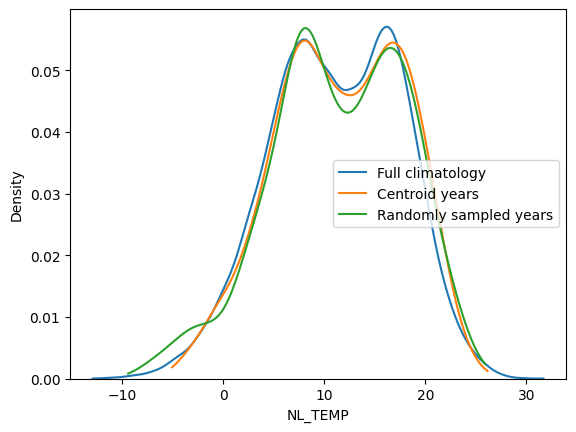

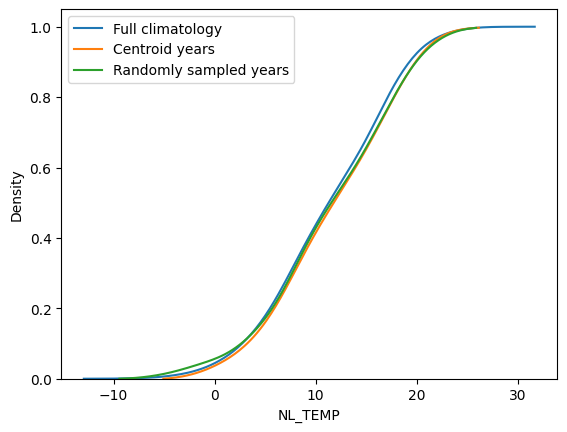

In [31]:
# just simple KDE plots for visual inspection. Don't know how useful.

col = "NL_TEMP"

plt.figure()
sns.kdeplot(df_daily[col], cut=0, label="Full climatology")
sns.kdeplot(df_centroids[col], cut=0, label="Centroid years")
sns.kdeplot(df_random[col], cut=0, label="Randomly sampled years")
plt.legend()

plt.figure()
sns.kdeplot(df_daily[col], cut=0, cumulative=True, label="Full climatology")
sns.kdeplot(df_centroids[col], cut=0, cumulative=True, label="Centroid years")
sns.kdeplot(df_random[col], cut=0, cumulative=True, label="Randomly sampled years")
plt.legend()

Column, KL_div centroids, KL_div random
NL_OFF 0.028060387193965537 0.02361382776994689
NL_ON 0.02847750608897958 0.023496182117601374
NL_SOLAR 0.027883510413669384 0.0365181845572192
NL_TEMP 0.03333754178660838 0.04218066285331569


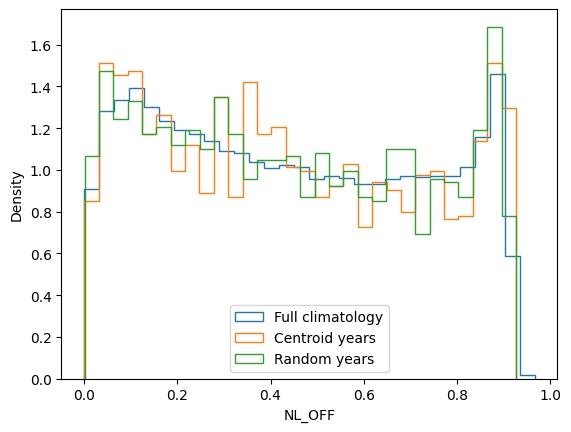

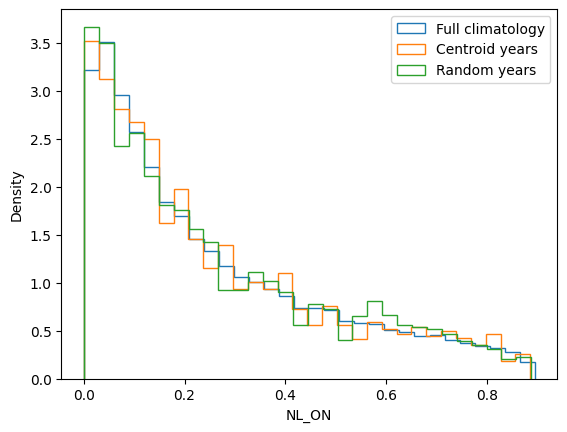

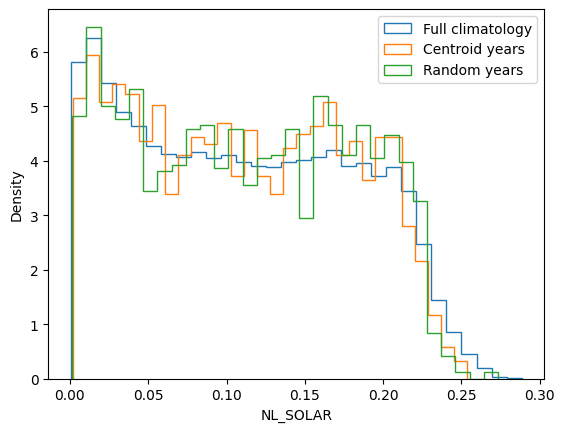

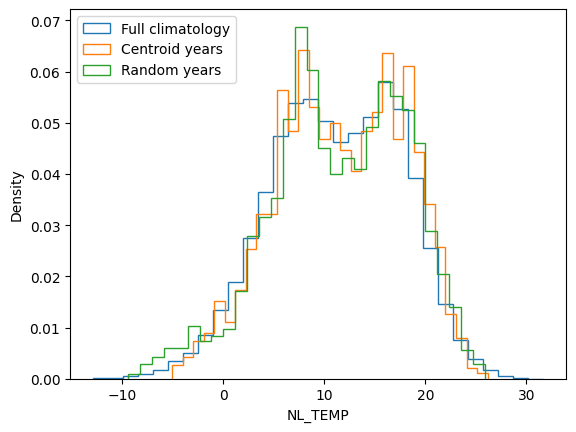

In [ ]:
# compute KL_div to quantify similarity between PDFs, lower (closer to 0) is better!

plot = True

# col = "NL_TEMP"
print("Column, KL_div centroids, KL_div random")
for col in COLS:
    ref = df_daily[col].to_numpy()
    cent = df_centroids[col].to_numpy()
    rnd = df_random[col].to_numpy()

    NUM_BINS = 100
    bins = np.linspace(ref.min(), ref.max(), NUM_BINS)
    pdf_ref, _ = np.histogram(ref, bins=bins, density=True)
    pdf_centroids, _ = np.histogram(cent, bins=bins, density=True)
    pdf_random, _ = np.histogram(rnd, bins=bins, density=True)

    # Lower entropy is better
    print(col, entropy(pdf_centroids, pdf_ref), entropy(pdf_random, pdf_ref))

    if plot:
        plt.figure()
        plt.hist(ref, bins=30, density=True, histtype="step", label="Full climatology")
        plt.hist(cent, bins=30, density=True, histtype="step", label="Centroid years")
        plt.hist(rnd, bins=30, density=True, histtype="step", label="Random years")
        plt.legend()
        plt.xlabel(col)
        plt.ylabel("Density")

In [ ]:
# study extreme statistics
data_map = {
    "ref": df_daily[COLS],
    "centroids": df_centroids[COLS],
    "random": df_random[COLS],
}
percentiles = (1, 5, 50, 95, 99)

rows = []
for name, df in data_map.items():
    for c in COLS:
        x = df[c].to_numpy()
        pvals = np.nanpercentile(x, percentiles)
        for p, v in zip(percentiles, pvals, strict=True):
            rows.append((name, c, p, float(v)))
df_percentiles = pd.DataFrame(
    rows, columns=["dataset", "variable", "percentile", "value"]
)

ref = (
    df_percentiles[df_percentiles["dataset"] == "ref"]
    .rename(columns={"value": "ref_value"})
    .loc[:, ["variable", "percentile", "ref_value"]]
)
out = df_percentiles.merge(ref, on=["variable", "percentile"], how="left")
out["diff_abs"] = out["value"] - out["ref_value"]
denom = np.where(np.abs(out["ref_value"]) < 1e-12, np.nan, out["ref_value"])
out["diff_rel_pct"] = 100.0 * out["diff_abs"] / denom

out.query('dataset == "centroids"')

,dataset,variable,percentile,value,ref_value,diff_abs,diff_rel_pct
20,centroids,NL_OFF,1,0.012634,0.015513,-0.002879,-18.559747
21,centroids,NL_OFF,5,0.049359,0.048695,0.000663,1.361896
22,centroids,NL_OFF,50,0.419655,0.430141,-0.010486,-2.437842
23,centroids,NL_OFF,95,0.887711,0.881559,0.006152,0.697860
24,centroids,NL_OFF,99,0.913178,0.911580,0.001597,0.175232
25,centroids,NL_ON,1,0.006732,0.006485,0.000248,3.821950
26,centroids,NL_ON,5,0.017228,0.018017,-0.000789,-4.379257
27,centroids,NL_ON,50,0.188425,0.187054,0.001371,0.733005
28,centroids,NL_ON,95,0.738149,0.732457,0.005692,0.777144
29,centroids,NL_ON,99,0.837013,0.847529,-0.010516,-1.240783


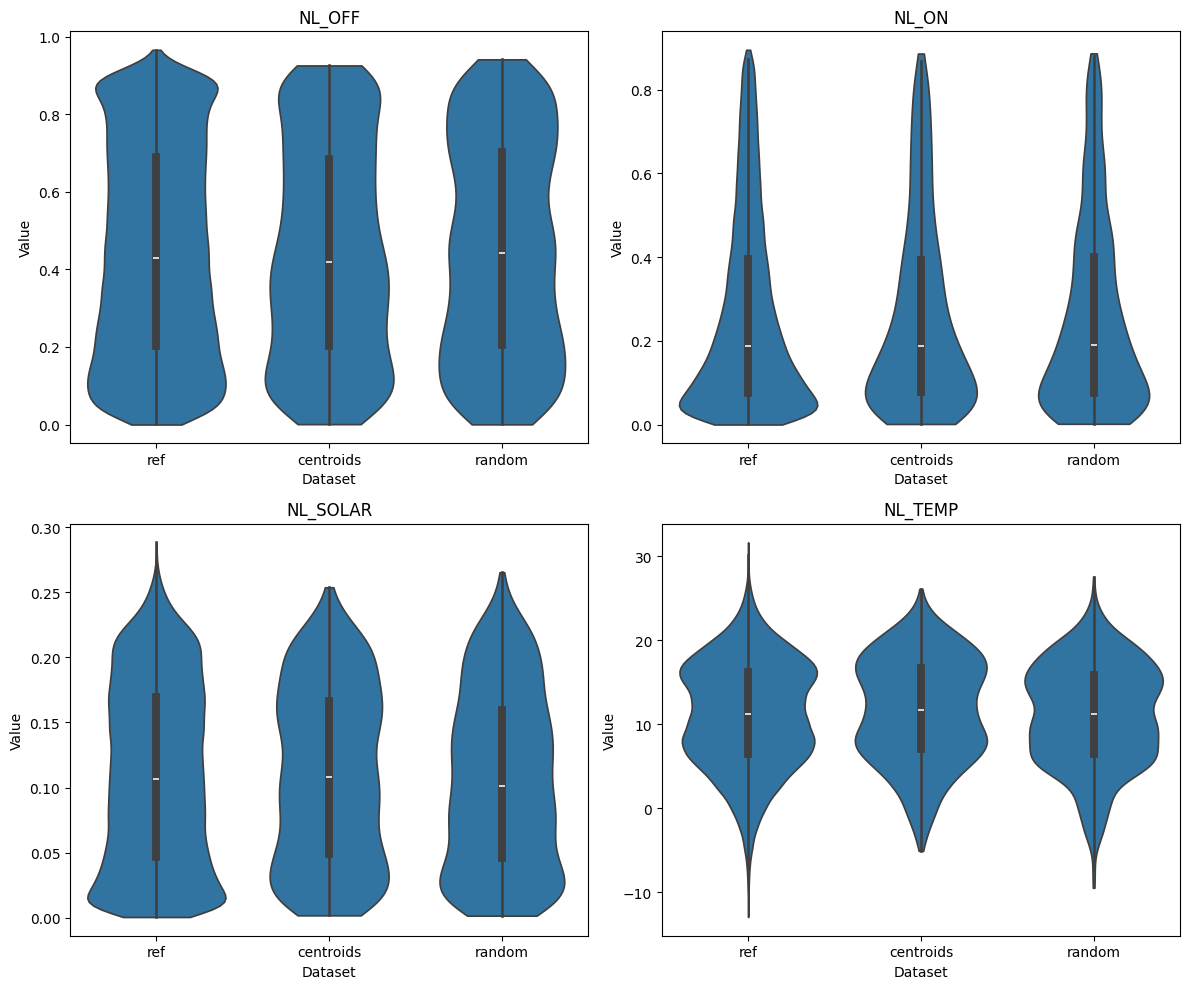

In [ ]:
# study extreme statistics
data_map = {
    "ref": df_daily[COLS],
    "centroids": df_centroids[COLS],
    "random": df_random[COLS],
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, c in enumerate(COLS):
    ax = axes[i]
    # Combine the data for seaborn
    data = []
    labels = []
    groups = []

    for name, df in data_map.items():
        data.extend(df[c].to_numpy())
        labels.extend([c] * len(df))
        groups.extend([name] * len(df))

    sns.violinplot(x=groups, y=data, ax=ax, cut=0)
    ax.set_title(c)
    ax.set_xlabel("Dataset")
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()
